In [2]:
%pip install -q langchain-text-splitters pypdf openai tiktoken sentence-transformers matplotlib pandas python-dotenv

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os, re, json, statistics
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from pypdf import PdfReader

from langchain_text_splitters import (
    CharacterTextSplitter,
    RecursiveCharacterTextSplitter,
    TokenTextSplitter,
)

In [4]:
load_dotenv()   # reads the .env file

if os.getenv("OPENAI_API_KEY"):
    print("API key found")
else:
    print("No API key found. Check your .env file (it is needed for transcription).")

API key found


In [5]:
AUDIO_PATH = Path("The_Blueprint_For_Trustworthy_AI.m4a")

print("Current working folder:", Path.cwd())
if AUDIO_PATH.exists():
    print(f"Audio found: {AUDIO_PATH.name} ({AUDIO_PATH.stat().st_size / 1_000_000:.1f} MB)")
else:
    print("Audio NOT FOUND. Move the file into the folder shown above.")

Current working folder: c:\Users\maxke\Desktop\Ironhack\Coursework\Week3\Day12\lab-chunking-strategies
Audio found: The_Blueprint_For_Trustworthy_AI.m4a (30.2 MB)


In [6]:
import subprocess, glob

TRANSCRIPT_PATH = Path("transcript.txt")

def transcribe_audio(audio_path, out_path, model="whisper-1", piece_seconds=600):
    """Transcribe audio with the OpenAI API and save the text. Skips all work if out_path already exists."""
    out = Path(out_path)
    if out.exists() and out.stat().st_size > 0:
        print(f"{out} already exists -> skipping transcription")
        return out.read_text(encoding="utf-8")

    # 1) shrink and cut the audio: mono, 64 kbps mp3, 10-minute pieces
    Path("_pieces").mkdir(exist_ok=True)
    subprocess.run(["ffmpeg", "-v", "error", "-y", "-i", str(audio_path), "-ac", "1", "-b:a", "64k",
                    "-f", "segment", "-segment_time", str(piece_seconds), "-reset_timestamps", "1",
                    "_pieces/piece_%02d.mp3"], check=True)

    # 2) transcribe the pieces in order
    from openai import OpenAI
    client = OpenAI()                                  # uses OPENAI_API_KEY from the environment
    texts = []
    for f in sorted(glob.glob("_pieces/piece_*.mp3")):
        with open(f, "rb") as fh:
            texts.append(client.audio.transcriptions.create(model=model, file=fh).text)
        print(f, "done")

    text = " ".join(texts)
    out.write_text(text, encoding="utf-8")             # save to a local file
    return text

podcast_text = transcribe_audio(AUDIO_PATH, TRANSCRIPT_PATH)
print(f"Podcast transcript length: {len(podcast_text)} chars")
print(podcast_text[:200])

transcript.txt already exists -> skipping transcription
Podcast transcript length: 16313 chars
So imagine for a second you're driving across I don't know a massive suspension bridge. OK. You don't pull over halfway across get out and demand to see the blueprints. Right. You don't interview the 


In [7]:
PDF_PATH = Path("ai_hleg_ethics_guidelines_for_trustworthy_ai-en.pdf")

def load_pdf(path=PDF_PATH):
    reader = PdfReader(path)
    return "\n".join(page.extract_text() or "" for page in reader.pages)

pdf_text = load_pdf()
print(f"PDF length: {len(pdf_text)} chars")
print(pdf_text[:200])

PDF length: 156411 chars
 
 
 
 
 
 
INDEPENDENT 
HIGH-LEVEL EXPERT GROUP ON 
ARTIFICIAL INTELLIGENCE 
SET UP BY THE EUROPEAN COMMISSION 
 
 
 
 
 
 
ETHICS GUIDELINES 
FOR TRUSTWORTHY AI 
 
 
 
 
 
 
ETHICS GUIDELINES FOR TR


In [8]:
import subprocess, glob

TRANSCRIPT_PATH = Path("transcript.txt")

def transcribe_audio(audio_path, out_path, model="whisper-1", piece_seconds=600):
    """Transcribe audio with the OpenAI API and save the text. Skips all work if out_path already exists."""
    out = Path(out_path)
    if out.exists() and out.stat().st_size > 0:
        print(f"{out} already exists -> skipping transcription")
        return out.read_text(encoding="utf-8")

    # 1) shrink and cut the audio: mono, 64 kbps mp3, 10-minute pieces
    Path("_pieces").mkdir(exist_ok=True)
    subprocess.run(["ffmpeg", "-v", "error", "-y", "-i", str(audio_path), "-ac", "1", "-b:a", "64k",
                    "-f", "segment", "-segment_time", str(piece_seconds), "-reset_timestamps", "1",
                    "_pieces/piece_%02d.mp3"], check=True)

    # 2) transcribe the pieces in order
    from openai import OpenAI
    client = OpenAI()                                  # uses OPENAI_API_KEY from the environment
    texts = []
    for f in sorted(glob.glob("_pieces/piece_*.mp3")):
        with open(f, "rb") as fh:
            texts.append(client.audio.transcriptions.create(model=model, file=fh).text)
        print(f, "done")

    text = " ".join(texts)
    out.write_text(text, encoding="utf-8")             # save to a local file
    return text

podcast_text = transcribe_audio(AUDIO_PATH, TRANSCRIPT_PATH)
print(f"Podcast transcript length: {len(podcast_text)} chars")
print(podcast_text[:200])

transcript.txt already exists -> skipping transcription
Podcast transcript length: 16313 chars
So imagine for a second you're driving across I don't know a massive suspension bridge. OK. You don't pull over halfway across get out and demand to see the blueprints. Right. You don't interview the 


In [9]:
PDF_PATH = Path("ai_hleg_ethics_guidelines_for_trustworthy_ai-en.pdf")

def load_pdf(path=PDF_PATH):
    reader = PdfReader(path)
    return "\n".join(page.extract_text() or "" for page in reader.pages)

pdf_text = load_pdf()
print(f"PDF length: {len(pdf_text)} chars")
print(pdf_text[:200])

PDF length: 156411 chars
 
 
 
 
 
 
INDEPENDENT 
HIGH-LEVEL EXPERT GROUP ON 
ARTIFICIAL INTELLIGENCE 
SET UP BY THE EUROPEAN COMMISSION 
 
 
 
 
 
 
ETHICS GUIDELINES 
FOR TRUSTWORTHY AI 
 
 
 
 
 
 
ETHICS GUIDELINES FOR TR


# Step 2

In [10]:
from langchain_text_splitters import CharacterTextSplitter

splitter = CharacterTextSplitter(
    separator="",
    chunk_size=500,
    chunk_overlap=0,
    length_function=len
)

podcast_chunks = splitter.split_text(podcast_text)

print("Number of chunks:", len(podcast_chunks))
print("First chunk length:", len(podcast_chunks[0]))
print("\nFirst chunk:\n", podcast_chunks[0])

Number of chunks: 33
First chunk length: 500

First chunk:
 So imagine for a second you're driving across I don't know a massive suspension bridge. OK. You don't pull over halfway across get out and demand to see the blueprints. Right. You don't interview the welding crew. No. You just you trust it. You just drive. You trust the bridge. You trust the engineering standards the inspections the laws that say this thing won't fail. Right. It's trust in the infrastructure. It's invisible but it's there. Exactly. But now let's switch gears. Think about the alg


In [11]:
pdf_chunks = splitter.split_text(pdf_text)

print("Number of PDF chunks:", len(pdf_chunks))
print("First PDF chunk length:", len(pdf_chunks[0]))
print("\nFirst PDF chunk:\n", pdf_chunks[0])

Number of PDF chunks: 313
First PDF chunk length: 488

First PDF chunk:
 INDEPENDENT 
HIGH-LEVEL EXPERT GROUP ON 
ARTIFICIAL INTELLIGENCE 
SET UP BY THE EUROPEAN COMMISSION 
 
 
 
 
 
 
ETHICS GUIDELINES 
FOR TRUSTWORTHY AI 
 
 
 
 
 
 
ETHICS GUIDELINES FOR TRUSTWORTHY AI 
 
High-Level Expert Group on Artificial Intelligence 
 
 
 
 
 
 
 
 
This document was written by the High-Level Expert Group on AI (AI HLEG) . The members of the AI HLEG 
named in this document support the overall framework for Trustworthy AI put forward in these Guidelines, 
althoug


In [12]:
chunk_sizes = [500, 1000, 2000]
overlap_values = [0, 50, 100]

documents = {
    "Podcast": podcast_text,
    "PDF": pdf_text
}

chunking_results = {}

for document_name, text in documents.items():
    print(f"\n{document_name}")

    for size in chunk_sizes:
        for overlap in overlap_values:

            splitter = CharacterTextSplitter(
                separator="",
                chunk_size=size,
                chunk_overlap=overlap,
                length_function=len
            )

            chunks = splitter.split_text(text)

            chunking_results[(document_name, size, overlap)] = chunks

            print(
                f"Size: {size} | "
                f"Overlap: {overlap} | "
                f"Chunks: {len(chunks)}"
            )


Podcast
Size: 500 | Overlap: 0 | Chunks: 33
Size: 500 | Overlap: 50 | Chunks: 37
Size: 500 | Overlap: 100 | Chunks: 41
Size: 1000 | Overlap: 0 | Chunks: 17
Size: 1000 | Overlap: 50 | Chunks: 18
Size: 1000 | Overlap: 100 | Chunks: 19
Size: 2000 | Overlap: 0 | Chunks: 9
Size: 2000 | Overlap: 50 | Chunks: 9
Size: 2000 | Overlap: 100 | Chunks: 9

PDF
Size: 500 | Overlap: 0 | Chunks: 313
Size: 500 | Overlap: 50 | Chunks: 348
Size: 500 | Overlap: 100 | Chunks: 391
Size: 1000 | Overlap: 0 | Chunks: 157
Size: 1000 | Overlap: 50 | Chunks: 165
Size: 1000 | Overlap: 100 | Chunks: 174
Size: 2000 | Overlap: 0 | Chunks: 79
Size: 2000 | Overlap: 50 | Chunks: 81
Size: 2000 | Overlap: 100 | Chunks: 83


## Step 2: Fixed-Size Chunking – Analysis and Findings

In this step, I implemented fixed-size chunking using LangChain's `CharacterTextSplitter`. I tested three chunk sizes (500, 1000, and 2000 characters) and three overlap values (0, 50, and 100 characters) on both the podcast transcript and the PDF document.

I used nested loops to test all 18 combinations and stored the resulting chunks in a dictionary for later comparison and analysis.

### Results and Observations

The results showed that increasing the chunk size reduced the total number of chunks, while increasing the overlap generally produced more chunks.

For example, with a chunk size of 500 characters, the podcast produced between 33 and 41 chunks, while the PDF produced between 313 and 391 chunks, depending on the overlap.

**Analysis Questions:**

**1. Does fixed-size chunking break sentences in the middle?**

Yes. I observed that both documents contained chunks that ended in the middle of a word or sentence. This happens because the splitter uses a fixed character count without considering the meaning or structure of the text.

**2. How does it handle paragraph boundaries?**

With `separator=""`, paragraph boundaries are not considered. The splitter divides the text based on character positions, even when this separates related information across different chunks.

**3. Which content type handles fixed-size chunking better?**

The podcast transcript mainly consists of continuous spoken text, while the PDF contains more structured content, including headings and paragraphs. Fixed-size chunking may be particularly problematic for the PDF because it does not preserve these structural boundaries. However, the current results are not sufficient to determine which content type performs better in retrieval.

### Conclusion

Fixed-size chunking is simple to implement and provides predictable chunk sizes. However, it can break sentences, separate related information, and ignore the original document structure.

Adding overlap can help preserve context between neighboring chunks, but it also increases the number of chunks and introduces duplicated content.

Overall, this experiment showed me that choosing an appropriate chunk size and overlap involves a trade-off between context preservation, retrieval precision, and processing efficiency. Further analysis is needed to determine which settings produce the most useful chunks for RAG.

# Step 3

In [13]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

chunk_sizes = [500, 1000, 2000]

separator_options = {
    "paragraph_first": ["\n\n", "\n", ". ", " ", ""],
    "sentence_first": [". ", "\n\n", "\n", " ", ""]
}

documents = {
    "Podcast": podcast_text,
    "PDF": pdf_text
}

recursive_results = {}

for document_name, text in documents.items():
    print(f"\n{document_name}")

    for size in chunk_sizes:
        for separator_name, separators in separator_options.items():

            splitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(
                encoding_name="cl100k_base",
                chunk_size=size,
                chunk_overlap=0,
                separators=separators
            )

            chunks = splitter.split_text(text)

            recursive_results[(document_name, size, separator_name)] = chunks

            print(
                f"Size: {size} tokens | "
                f"Priority: {separator_name} | "
                f"Chunks: {len(chunks)}"
            )


Podcast
Size: 500 tokens | Priority: paragraph_first | Chunks: 7
Size: 500 tokens | Priority: sentence_first | Chunks: 7
Size: 1000 tokens | Priority: paragraph_first | Chunks: 4
Size: 1000 tokens | Priority: sentence_first | Chunks: 4
Size: 2000 tokens | Priority: paragraph_first | Chunks: 2
Size: 2000 tokens | Priority: sentence_first | Chunks: 2

PDF
Size: 500 tokens | Priority: paragraph_first | Chunks: 71
Size: 500 tokens | Priority: sentence_first | Chunks: 72
Size: 1000 tokens | Priority: paragraph_first | Chunks: 36
Size: 1000 tokens | Priority: sentence_first | Chunks: 34
Size: 2000 tokens | Priority: paragraph_first | Chunks: 20
Size: 2000 tokens | Priority: sentence_first | Chunks: 17


In [14]:
for document_name in ["Podcast", "PDF"]:
    for priority in ["paragraph_first", "sentence_first"]:

        chunks = recursive_results[(document_name, 500, priority)]

        print(f"\n--- {document_name} | {priority} ---")
        print("End of chunk 1:", repr(chunks[0][-150:]))
        print("Start of chunk 2:", repr(chunks[1][:150]))


--- Podcast | paragraph_first ---
End of chunk 1: 're. The source material defines trustworthy A.I. as having three components. Right. And they have to exist through the entire life cycle of the system'
Start of chunk 2: '. Not just at launch not just at launch from design to retirement. Think of it like a three legged stool. The first leg is lawful. The A.I. has to com'

--- Podcast | sentence_first ---
End of chunk 1: 're. The source material defines trustworthy A.I. as having three components. Right. And they have to exist through the entire life cycle of the system'
Start of chunk 2: '. Not just at launch not just at launch from design to retirement. Think of it like a three legged stool. The first leg is lawful. The A.I. has to com'

--- PDF | paragraph_first ---
End of chunk 1: 'sole responsibility of the High-\nLevel Expert Group on Artificial Intelligence (AI HLEG). Although Commission staff facilitated the preparation of the'
Start of chunk 2: 'Guidelines, the views expressed

In [15]:
for priority in ["paragraph_first", "sentence_first"]:
    print(f"\n--- PDF | {priority} ---")

    chunks = recursive_results[("PDF", 500, priority)]

    for i, chunk in enumerate(chunks):
        position = chunk.upper().find("INTRODUCTION")

        if position != -1:
            print(f"\nChunk {i + 1}, position {position}:")
            print(repr(chunk[max(0, position - 80):position + 160]))


--- PDF | paragraph_first ---

Chunk 2, position 727:
'he copyright holders.  \n1 \n \n \n \nTABLE OF CONTENTS \n \n \nEXECUTIVE SUMMARY 2 \nA. INTRODUCTION 4 \nB. A FRAMEWORK FOR TRUSTWORTHY AI 6 \nI. Chapter I: Foundations of Trustworthy AI 9 \nII. Chapter II: Realising Trustworthy AI   14 \n1.    Require'

Chunk 5, position 1533:
'of current or future policymaking or regulation, nor do they  \naim to deter the introduction thereof . They should be seen as a living document to be reviewed and updated over \ntime to ensure their continuous relevance as the technology , o'

Chunk 6, position 443:
' and \npublished in December 2018 by the Commission and Member States.  \n4 \n \nA. INTRODUCTION \nIn its Communication of 25 April 2018 and 7 December 2018, the European Commission set out its vision for \nartificial i ntelligence (AI), which su'

Chunk 45, position 622:
'y, organisation or institution fosters the acceptance \nand the relevance of the introduction of any new process (whethe

## Step 3: Recursive Character Chunking – Analysis and Findings

In this step, I implemented recursive chunking using LangChain's `RecursiveCharacterTextSplitter`. I tested chunk sizes of 500, 1000, and 2000 tokens with two different separator priorities (`paragraph_first` and `sentence_first`) for both the podcast transcript and the PDF.

### Results and Observations

Increasing the chunk size reduced the number of chunks for both documents. The separator priority had little visible impact on the podcast results, but it produced noticeable differences in the PDF.

**Analysis Questions:**

**1. Does recursive chunking preserve sentence boundaries better?**

Partially. Compared to fixed-size chunking, recursive splitting generally preserved word boundaries better in our inspected examples. However, some sentences were still split across chunks, and punctuation sometimes ended up at the beginning of the next chunk.

**2. How does it handle the podcast's conversational structure?**

Both separator configurations produced the same number of chunks and identical boundaries in the inspected example. Since the podcast transcript contains mostly continuous spoken text, the splitter did not explicitly recognize conversational transitions or speaker changes.

**3. Does it respect PDF section headers?**

Not consistently. The `paragraph_first` configuration preserved the heading `A. INTRODUCTION` in our example, while `sentence_first` separated the heading incorrectly, leaving `. INTRODUCTION`. This demonstrated how separator priorities can unintentionally damage document structure.

### Conclusion

Recursive chunking offers more control over text boundaries than fixed-size chunking, but its effectiveness depends on the document structure and separator configuration.

The experiment showed that prioritizing paragraphs can be useful for structured documents, while sentence-based splitting is not always reliable due to punctuation used in headings or abbreviations.

Since Step 2 used character-based sizes and Step 3 used token-based sizes, the chunk counts are not directly comparable. A more detailed quality evaluation will be necessary to determine which strategy is better suited for each content type.

# Step 4

In [16]:
splitter = TokenTextSplitter(encoding_name="cl100k_base", chunk_size=300, chunk_overlap=50)
pdf_token_chunks = splitter.split_text(pdf_text)
podcast_token_chunks = splitter.split_text(podcast_text)
print(len(pdf_token_chunks), "PDF chunks,", len(podcast_token_chunks), "podcast chunks")

127 PDF chunks, 14 podcast chunks


In [17]:
import tiktoken

encoding = tiktoken.get_encoding("cl100k_base")

for name, chunks in [
    ("Podcast", podcast_token_chunks),
    ("PDF", pdf_token_chunks)
]:
    print(f"\n--- {name} ---")

    print("First chunk token count:",
          len(encoding.encode(chunks[0])))

    print("End of chunk 1:",
          repr(chunks[0][-150:]))

    print("Start of chunk 2:",
          repr(chunks[1][:150]))


--- Podcast ---
First chunk token count: 300
End of chunk 1: "his for everyone listening this document it went public in April 2019 in tech years. That's practically the stone age is we didn't have the generative"
Start of chunk 2: ' a mix of academics industry leaders and civil society a really broad group. And just to frame this for everyone listening this document it went publi'

--- PDF ---
First chunk token count: 300
End of chunk 1: 'uropean Commission  \nB-1049 Brussels  \n \nDocument made public on 8 April 2019.  \n \nA first draft of this document was released on 18 December 2018 and'
Start of chunk 2: '-HLG-AI@ec.europa.eu  \n \nEuropean Commission  \nB-1049 Brussels  \n \nDocument made public on 8 April 2019.  \n \nA first draft of this document was releas'


In [18]:
for name in ["Podcast", "PDF"]:

    fixed_chunks = chunking_results[(name, 500, 0)]

    token_counts = [
        len(encoding.encode(chunk))
        for chunk in fixed_chunks
    ]

    print(f"\n--- {name}: Fixed-Size Chunking ---")
    print("Minimum tokens:", min(token_counts))
    print("Maximum tokens:", max(token_counts))
    print("Average tokens:", round(sum(token_counts) / len(token_counts), 1))


--- Podcast: Fixed-Size Chunking ---
Minimum tokens: 73
Maximum tokens: 119
Average tokens: 103.6

--- PDF: Fixed-Size Chunking ---
Minimum tokens: 78
Maximum tokens: 160
Average tokens: 102.3


## Step 4: Token-Based Chunking – Analysis and Findings

In this step, I implemented token-based chunking using LangChain's `TokenTextSplitter` with the `cl100k_base` tokenizer. I used a chunk size of 300 tokens and an overlap of 50 tokens for both documents.

### Results and Observations

The token-based approach produced 127 chunks for the PDF and 14 chunks for the podcast transcript. I verified that the first chunks contained exactly 300 tokens and that the overlap successfully repeated content between neighboring chunks.

To compare token-based and character-based chunking, I also measured the token counts of our previous 500-character chunks.

The results showed that the podcast chunks contained between 73 and 119 tokens, while the PDF chunks ranged from 78 to 160 tokens.

This demonstrated that a fixed number of characters does not correspond to a fixed number of tokens.

### Conclusion

Token-based chunking provides more precise control over token limits, which is particularly useful when working with LLM context windows.

However, similar to fixed-size chunking, it does not consider sentence or paragraph boundaries. As observed in both documents, sentences can still be split across chunks.

Overall, I learned that token-based chunking is useful for controlling context size, while recursive chunking may be better suited for preserving natural text boundaries. The best approach depends on the requirements of the RAG application.

# Step 6

In [19]:
import pandas as pd

results = []

for document_name in ["Podcast", "PDF"]:

    strategies = {
        "Fixed-500": chunking_results[(document_name, 500, 0)],
        "Recursive-1000": recursive_results[(document_name, 1000, "paragraph_first")],
        "Token-300": podcast_token_chunks if document_name == "Podcast" else pdf_token_chunks
    }

    for strategy_name, chunks in strategies.items():

        sizes = [len(chunk) for chunk in chunks]

        results.append({
            "Document": document_name,
            "Strategy": strategy_name,
            "Avg chunk size (chars)": round(sum(sizes) / len(sizes), 1),
            "Min": min(sizes),
            "Max": max(sizes),
            "# of chunks": len(chunks)
        })

comparison_df = pd.DataFrame(results)

display(comparison_df)

,Document,Strategy,Avg chunk size (chars),Min,Max,# of chunks
0,Podcast,Fixed-500,494.2,313,500,33
1,Podcast,Recursive-1000,4078.2,1812,4869,4
2,Podcast,Token-300,1388.1,574,1557,14
3,PDF,Fixed-500,497.7,382,500,313
4,PDF,Recursive-1000,4336.5,541,5013,36
5,PDF,Token-300,1477.9,748,1724,127


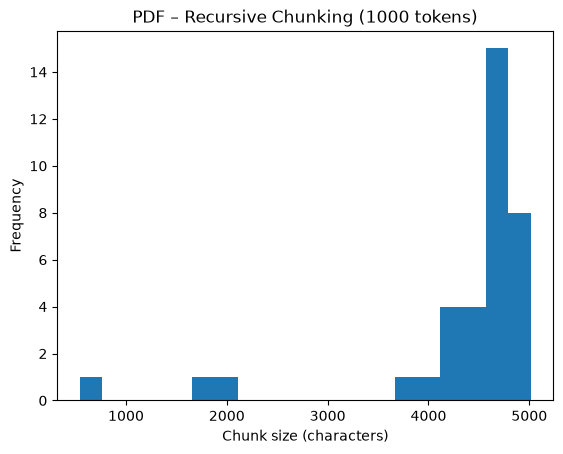

In [20]:
import matplotlib.pyplot as plt

# Get the PDF chunks created with the recursive splitter.
pdf_recursive_chunks = recursive_results[("PDF", 1000, "paragraph_first")]

# Calculate the character length of each chunk.
chunk_lengths = [len(chunk) for chunk in pdf_recursive_chunks]

# Plot the distribution of chunk sizes.
plt.hist(chunk_lengths, bins=20)
plt.xlabel("Chunk size (characters)")
plt.ylabel("Frequency")
plt.title("PDF – Recursive Chunking (1000 tokens)")
plt.show()

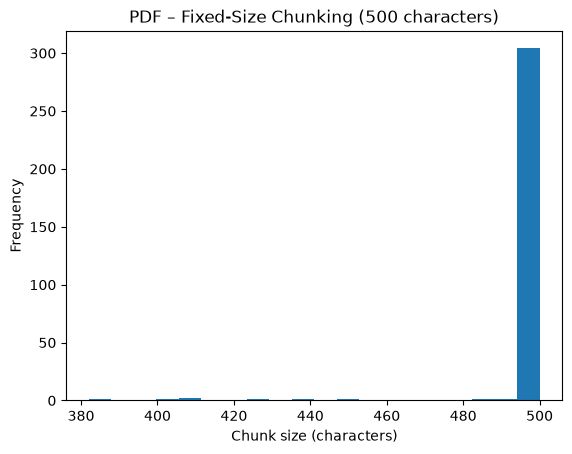

In [21]:
# Get PDF chunks from fixed-size chunking
pdf_fixed_chunks = chunking_results[("PDF", 500, 0)]

# Calculate character lengths
fixed_chunk_lengths = [len(chunk) for chunk in pdf_fixed_chunks]

# Plot chunk size distribution
plt.hist(fixed_chunk_lengths, bins=20)
plt.xlabel("Chunk size (characters)")
plt.ylabel("Frequency")
plt.title("PDF – Fixed-Size Chunking (500 characters)")
plt.show()

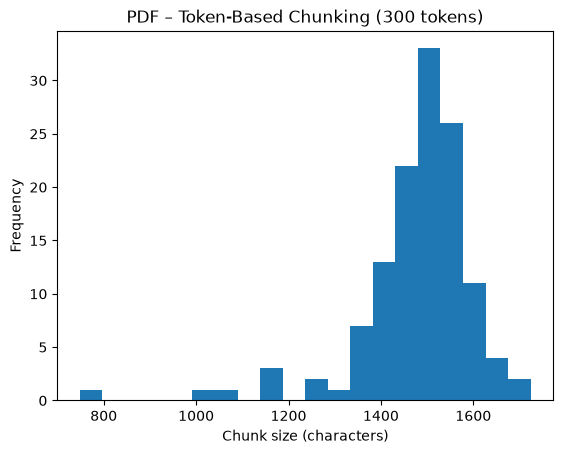

In [22]:
# Get character lengths of token-based PDF chunks
token_chunk_lengths = [len(chunk) for chunk in pdf_token_chunks]

# Plot chunk size distribution
plt.hist(token_chunk_lengths, bins=20)
plt.xlabel("Chunk size (characters)")
plt.ylabel("Frequency")
plt.title("PDF – Token-Based Chunking (300 tokens)")
plt.show()

In [23]:
for document_name in ["Podcast", "PDF"]:

    strategies = {
        "Fixed-500": chunking_results[(document_name, 500, 0)],
        "Recursive-1000": recursive_results[(document_name, 1000, "paragraph_first")],
        "Token-300": podcast_token_chunks if document_name == "Podcast" else pdf_token_chunks
    }

    print(f"\n--- {document_name} ---")

    for strategy_name, chunks in strategies.items():
        print(f"\n{strategy_name}")

        for i, chunk in enumerate(chunks[:3]):
            print(f"Chunk {i + 1} ends with: {repr(chunk[-50:])}")


--- Podcast ---

Fixed-500
Chunk 1 ends with: "y. But now let's switch gears. Think about the alg"
Chunk 2 ends with: 'guidelines for trustworthy A.I. This is a heavy hi'
Chunk 3 ends with: "s specific report. Because it's not dusty. It's th"

Recursive-1000
Chunk 1 ends with: 'ias and discrimination. Basically ensuring the A.I'
Chunk 2 ends with: "g will appreciate identification. It's simple. A.I"
Chunk 3 ends with: 'onomous weapon systems. Killer robots, effectively'

Token-300
Chunk 1 ends with: "lly the stone age is we didn't have the generative"
Chunk 2 ends with: "eels like a pretty low bar. Don't break the law. I"
Chunk 3 ends with: ". It's a tool for human flourishing. I highlighted"

--- PDF ---

Fixed-500
Chunk 1 ends with: 'orthy AI put forward in these Guidelines, \nalthoug'
Chunk 2 ends with: 'rt group that was set up by the European Commissio'
Chunk 3 ends with: 's first draft, which was considered in the prepara'

Recursive-1000
Chunk 1 ends with: 'omponents, society s

## Step 6: Visualize and Compare Results – Analysis and Findings

In this step, I compared the three chunking strategies using a pandas DataFrame and matplotlib histograms. I analyzed the average, minimum, and maximum chunk sizes, as well as the total number of chunks for both documents.

### Results and Observations

The histograms showed clear differences between the strategies:

- **Fixed-Size Chunking:** Produced very consistent chunk lengths, with almost all PDF chunks close to 500 characters.
- **Recursive Character Chunking:** Produced more variable chunk lengths, with most PDF chunks between 4,000 and 5,000 characters in our 1,000-token configuration.
- **Token-Based Chunking:** Produced PDF chunks mostly between 1,400 and 1,600 characters, demonstrating that a fixed token count does not result in a fixed character count.

### Chunk Boundary Analysis

I also inspected the last 50 characters of the first three chunks for each strategy.

Fixed-size chunking frequently broke words in the middle, such as `alg` in the podcast and `althoug` in the PDF.

Recursive chunking sometimes preserved complete sentences, particularly in the PDF, but still produced incomplete sentences in other cases.

Token-based chunking also interrupted sentences because it prioritizes token counts rather than natural language boundaries.

### Conclusion and Trade-offs

The comparison demonstrated that each strategy has different advantages and limitations.

Fixed-size chunking provides consistent character lengths but often breaks important context. Recursive chunking can preserve natural text boundaries better, depending on the separators and document structure. Token-based chunking offers better control over LLM token limits but does not guarantee meaningful boundaries.

Since the tested configurations used different chunk sizes and overlap settings, these results are descriptive rather than a controlled performance comparison.

Overall, I learned that consistent chunk sizes do not necessarily indicate good chunk quality. Preserving meaningful context is equally important for RAG applications.

# Step 7

In [24]:
def pct_clean_boundaries(chunks):
    if not chunks:
        return 0.0

    clean = sum(
        1 for chunk in chunks
        if chunk.strip().endswith((".", "?", "!"))
    )

    return clean / len(chunks) * 100


# Test with fixed-size PDF chunks
fixed_pdf_chunks = chunking_results[("PDF", 500, 0)]

print(f"PDF Fixed-500: {pct_clean_boundaries(fixed_pdf_chunks):.1f}% clean endings")

PDF Fixed-500: 2.2% clean endings


In [25]:
boundary_results = []

for document_name in ["Podcast", "PDF"]:

    strategies = {
        "Fixed-500": chunking_results[(document_name, 500, 0)],
        "Recursive-1000": recursive_results[(document_name, 1000, "paragraph_first")],
        "Token-300": podcast_token_chunks if document_name == "Podcast" else pdf_token_chunks
    }

    for strategy_name, chunks in strategies.items():

        clean_pct = pct_clean_boundaries(chunks)

        boundary_results.append({
            "Document": document_name,
            "Strategy": strategy_name,
            "Clean endings (%)": round(clean_pct, 1),
            "# of chunks": len(chunks)
        })

boundary_df = pd.DataFrame(boundary_results)

display(boundary_df)

,Document,Strategy,Clean endings (%),# of chunks
0,Podcast,Fixed-500,9.1,33
1,Podcast,Recursive-1000,25.0,4
2,Podcast,Token-300,7.1,14
3,PDF,Fixed-500,2.2,313
4,PDF,Recursive-1000,30.6,36
5,PDF,Token-300,6.3,127


## Step 7: Chunk Quality Analysis

Recursive Character Chunking achieved the highest percentage of clean sentence endings for both the podcast (25.0%) and the PDF (30.6%), outperforming fixed-size and token-based chunking in this metric.

This suggests that recursive splitting is better at preserving natural text boundaries because it prioritizes separators such as paragraphs and spaces rather than cutting strictly by character or token count.

However, clean sentence endings do not necessarily guarantee meaningful context preservation, and the different chunk sizes and small podcast sample limit the reliability of a direct quality comparison.

# Step 8

## Step 8: Chunking Strategy Recommendations

### Summary of Results

I compared three chunking strategies across the PDF document and podcast transcript. The following table summarizes the clean-boundary percentages from Step 7.

| Strategy | Podcast Clean Endings | PDF Clean Endings |
|---|---:|---:|
| Fixed-Size (500 characters) | 9.1% | 2.2% |
| Recursive (1000 tokens) | 25.0% | 30.6% |
| Token-Based (300 tokens) | 7.1% | 6.3% |

Recursive chunking achieved the highest percentage of clean sentence endings for both documents. However, the tested configurations had different chunk sizes and overlap values, so these results do not prove which strategy would achieve the best retrieval performance.

### For PDF Documents

**Recommended Strategy:** Recursive Character Chunking

**Reasoning:**
- PDFs often contain structured content such as headings, paragraphs, and sections.
- Recursive chunking can preserve these boundaries better than fixed-size splitting.
- In our tests, it achieved the highest clean-boundary percentage for the PDF (30.6%).
- The `paragraph_first` configuration preserved the inspected section heading better than `sentence_first`.

**Recommended starting configuration:** 1000 tokens, paragraph-first separators, and 0 overlap, based on our tested setup. A small overlap could be evaluated later to improve context preservation.

### For Podcast Transcripts

**Recommended Strategy:** Token-Based Chunking with Overlap

**Reasoning:**
- Podcast transcripts usually contain continuous conversational text with fewer clear paragraph boundaries.
- Token-based chunking provides predictable token counts for LLM integration.
- Overlapping chunks can help preserve information across chunk boundaries.
- Recursive chunking achieved a higher clean-boundary score, but our podcast sample contained only four recursive chunks, making that result less reliable.

**Recommended starting configuration:** 300 tokens with 50 tokens overlap, as tested in Step 4.

This is a practical starting point rather than a proven optimal configuration. Further testing would be needed to evaluate whether it preserves conversational context better than recursive chunking.

### Trade-offs Summary

| Strategy | Pros | Cons | Best For |
|---|---|---|---|
| Fixed-Size | Simple, predictable character lengths | Can break words and sentences | Basic text processing and simple baselines |
| Recursive | Better preservation of natural text boundaries | Depends on separator configuration | Structured PDFs and documents |
| Token-Based | Direct control over token counts | Can interrupt sentences and context | LLM integration and token-budget management |
| Semantic | Groups text based on meaning | More complex and computationally expensive | Documents with changing topics and complex content |

*Semantic chunking was not implemented in this lab. Its advantages and limitations are based on the general concept rather than experimental results.*

### Final Conclusion

This lab demonstrated that choosing a chunking strategy involves trade-offs between chunk size, context preservation, and processing efficiency.

For structured PDF documents, I would prefer recursive chunking because it better preserves natural text boundaries in our experiments. For podcast transcripts, I would consider token-based chunking with overlap because it offers predictable token sizes and can preserve some context between neighboring chunks.

However, evaluating chunk boundaries alone is not enough to determine the best strategy for a real RAG application. A future improvement would be to compare retrieval relevance and answer quality using identical test questions across the different strategies.

In [26]:
question = "What are the three components of Trustworthy AI according to the EU Ethics Guidelines?"

reader = PdfReader(PDF_PATH)

for page_number, page in enumerate(reader.pages, start=1):
    text = page.extract_text() or ""
    position = text.lower().find("lawful")

    if position != -1:
        excerpt = text[max(0, position - 250):position + 500]

        print("Question:", question)
        print("Source: EU Ethics Guidelines for Trustworthy AI")
        print("PDF page:", page_number)
        print("\nRetrieved evidence:")
        print(excerpt)
        break
else:
    print("No matching evidence found.")

Question: What are the three components of Trustworthy AI according to the EU Ethics Guidelines?
Source: EU Ethics Guidelines for Trustworthy AI
PDF page: 4

Retrieved evidence:
2 
 
EXECUTIVE SUMMARY 
The aim of the Guidelines is to promote Trustworthy AI. Trustworthy AI has three components, which should be 
met throughout the system's entire life cycle : (1) it should be lawful, complying with  all applicable laws  and 
regulations (2) it should be ethical, ensuring adherence to ethical principles and values and (3) it should be robust, 
both from a technical and social perspective  since, even with good intentions, AI systems can cause unintentional 
harm. Each component in itself is necessary but not sufficient for the achievement of  Trustworthy AI. Ideally, all 
three components work in harmony and overlap in their operation.  If, in practic e, tensions aris
